In [86]:
from dotenv import load_dotenv
from pyarrow.lib import Sequence

load_dotenv()

from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import BaseMessage, SystemMessage, ToolMessage, HumanMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode

In [87]:
model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")


In [88]:
document_content=""

In [89]:
class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]


In [90]:
@tool
def update(content: str) -> str:
    """Update the document with the provided content"""
    global document_content
    document_content = content
    return f"Document has been updated successfully. The current content is : \n {document_content}"


@tool
def save(filename: str) -> str:
    """Save the current document to a text file and finish the process.
        Args :
        filename: name of the file
    """
    global document_content

    if not filename.endswith(".txt"):
        filename = filename + ".txt"

    try:
        with open(filename, 'w') as file:
            file.write(document_content)
            success_msg = f"document saved successfully as {filename}"
        print(success_msg)
        return success_msg
    except Exception as e:
        error_msg = f"Error savings the document : {e}"
        print(error_msg)
        return error_msg


In [91]:

AGENT_NODE = 'AGENT_NODE'
TOOLS_NODE = 'tools'

tools = [update, save]

model = model.bind_tools(tools)


def out_agent(state: AgentState) -> AgentState:
    system_prompt = SystemMessage(
        content=f"""
        You are an email drafter , a helpfully assistant , you are going to help the user to update and modify the document.
        - if the user wants to update or modify the content , use 'update' tools with the complete updated content
        - if the user wants to save and finish , you need to use the 'save' tools
        - Make sure to always show current document state after modification

    The current document is : {document_content}
    """)
    if not state['messages']:
        user_input = input("I am ready to help you update a document, what would you like to crate")
        print(f"\n {user_input} \n")
        user_msg = HumanMessage(content=user_input)
    else:
        user_input = input("what would you like to do with this document")
        print(f"\n {user_input} \n")
        user_msg = HumanMessage(content=user_input)

    all_messages = [system_prompt] + list(state['messages']) + [user_msg]
    response = model.invoke(all_messages)

    print(f"AI : {response.text}")

    if hasattr(response, "tool_calls") and response.tool_calls:
        print(f"Invoking tool: {[tc['name'] for tc in response.tool_calls]}\n")
    state['messages'] = list(state['messages']) + [user_msg, response]
    return state


def should_continue(state: AgentState):
    """Determine if we should continue or end the conversation"""
    messages = state['messages']
    if not messages:
        return 'continue'
    for message in reversed(messages):
        if (isinstance(message, ToolMessage)
                and "saved" in message.text.lower()
                and "document" in message.text.lower()):
            return 'end'
    return 'continue'


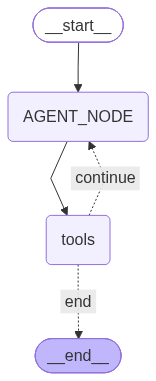

In [92]:

graph = StateGraph(AgentState)
graph.add_node(AGENT_NODE, out_agent)

tools_node = ToolNode(tools=tools)
graph.add_node(TOOLS_NODE, tools_node)

graph.add_edge(START, AGENT_NODE)
graph.add_edge(AGENT_NODE, TOOLS_NODE)

graph.add_conditional_edges(
    TOOLS_NODE, should_continue,
    {
        'end': END,
        'continue': AGENT_NODE
    }
)

bot = graph.compile()
bot

In [93]:
def print_messages(messages):
    """Function made to print the message in more readable format"""
    if not messages:
        return
    for message in messages[-3]:
        if isinstance(message, ToolMessage):
            print(f"ToolMessage: {message.content} ")


def run_document_agent():
    state = {"messages": []}
    for step in bot.stream(state):
        if 'messages' in step:
            print_messages(step['messages'])
    print("Application Exit.....")

run_document_agent()


KeyboardInterrupt: Interrupted by user